# Experiment: CDSTraj-style (characterized diffusion)

Liao et al., 2024 (arXiv 2405.02145), the joint-best 5 s NGSIM result found (2.85 m). A spatial-temporal interaction network (temporal initializer, spatial interaction, temporal deepening, confidence fusion) conditions a 'characterized' diffusion model of the future; the paper trains in two stages, the first with MSE. Paper: 0.36 / 0.86 / 1.36 / 2.02 / 2.85 m.

Part of the model comparison in `experiments/MODEL_ALTERNATIVES.md`. Run All; set `DEBUG = False` in section 2 for the real run.

## 0. Decisions & assumptions

Every choice that could change the result is listed here; the cell notes below repeat the ones that apply to each cell.

**Shared by every notebook (S)**

| # | Decision / assumption | Why | Departure from paper / alternative |
|---|---|---|---|
| S1 | Same data for every model: NGSIM us-101 + i-80 (DEBUG: first 250k rows of us-101), scene-level 70/10/20 split, seed 42, train-only normalization. | Differences in the results must come from the model, not the data. | Papers use their own splits, so published numbers are not like-for-like with ours. |
| S2 | Same training budget for every model: config.py defaults (12 epochs, Adam lr 5e-4 decayed x0.6 per epoch, batch 128, weight decay 1e-5, grad clip 1.0). | A fair comparison; per-model tuning would favour whichever model got tuned most. | Each paper's own schedule (e.g. CS-LSTM trains longer with lr 1e-3). Tune later with --mode tune if a model looks under-trained. |
| S3 | Loss = MSE + bivariate-Gaussian NLL + neighbour-goal MSE (`basic_loss`); the risk-scaled loss is used only where this notebook's M table says so (STRAP-R-based variants). Models without a goal head output zero goals, so their goal term is a constant. A model may add its own `aux_loss` (only the diffusion model does). | Keeps one training objective; the risk-scaled loss is STRAP-R's own contribution. | Loss values are therefore not comparable across models: compare RMSE only. |
| S4 | Best checkpoint = lowest validation loss (`fit` default); test RMSE is reported at 1-5 s for that checkpoint. | Same selection rule for every model. | Selecting on val RMSE would be closer to the reported metric. |
| S5 | KNOWN LIMITATION (not fixed): positions are relative to the target at each timestep, so the target's own history is always (0, 0) and lateral speed is always 0 (NGSIM gives longitudinal speed only). The target is seen through speed, acceleration and lane features; lateral context comes from neighbours. | Kept as is (user decision) so every model gets identical inputs. | Papers feed the target's own x/y track; lane-change prediction is handicapped for all models here. |
| S6 | Neighbours = up to 15 risk-selected vehicles (S/O-field > RISK_THRESHOLD), not every nearby vehicle. | Same scene construction as STRAP. | Grid/graph papers use all vehicles in range; ours see only the risk-selected ones. |
| S7 | Output = one bivariate Gaussian per future step (mu_x, mu_y, sigma_x, sigma_y, rho); RMSE uses the mean. Multimodal models are moment-matched to one Gaussian. | The `fit` / `evaluate_trajectory` contract and how STRAP's Table I is scored. | minADE/minFDE over modes would favour multimodal models. |

**Specific to this model (M)**

| # | Decision / assumption | Why | Departure from paper / alternative |
|---|---|---|---|
| M1 | Encoder: per-vehicle LSTM (temporal initializer), per-step target-to-neighbour attention (spatial interaction), 1 transformer layer over time (temporal deepening), confidence fusion = sigmoid gate between the target's own and the interaction sequence. | The paper's four encoder stages. | ASSUMPTION: exact layers not public. |
| M2 | Stage 1 (regression head) = the training-mode output, trained by the shared loss (paper's first stage uses MSE). | Gives a usable prediction early and conditions nothing else. | Paper trains two stages sequentially; ours trains both jointly. |
| M3 | Diffusion on the FULL future (divided by 30 m), not a residual: 100 steps, betas 1e-4..0.2; the denoiser is a 2-layer transformer over the 50 future steps whose tokens cross-attend to the encoder sequence ('characterized' = conditioned per step on scene features). | Distinct from `c2f_tp`, which diffuses a residual with an MLP. | ASSUMPTION: our interpretation of characterized diffusion. |
| M4 | Denoising loss via `aux_loss`. | Needs the true future. | - |
| M5 | Eval-mode output: 16 deterministic DDIM samples (10 steps), mean and spread -> Gaussian; rho = 0. | Single-Gaussian contract (S7). | - |

## 1. Setup

**Decisions in this cell:** seed fixed to `SEED` (42) in every notebook so initialisation is not a source of differences (S1).

In [1]:
import sys
from pathlib import Path

# Repo root = first folder upwards that contains src/ (works from experiments/ or the root).
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import time
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

from src.config import (
    BATCH_SIZE, BETA_LOSS, DEBUG_MAX_ROWS, DEVICE, DROPOUT, DT, LEARNING_RATE, LR_DECAY, N_V,
    NGSIM_LOCATIONS, NUM_EPOCHS, NORMALIZATION_FILE, SEED, STATE_DIM, TF_STEPS, TH_STEPS, WEIGHT_DECAY,
)
from src.data.loader import NGSIMDataLoader, create_dataloader
from src.data.normalization import load_stats, normalize_samples
from src.evaluation.evaluate import evaluate_trajectory
from src.models.strap import STRAP
from src.pipeline import collision_scores, metric_rows, test_groups
from src.train import fit, prepare_data
from experiments.benchmark import compare, save_result

torch.manual_seed(SEED)
print("device:", DEVICE)

/home/st_students/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


device: cuda


## 2. Experiment config

**Decisions in this cell:** training budget is config.py's (S2); `use_risk_loss` as in the M table; collisions scored at 2 m like `--mode collisions`.

In [2]:
EXP_NAME = "cdstraj"          # unique per notebook -> experiments/results/<EXP_NAME>.json
DESCRIPTION = "CDSTraj-style: spatial-temporal interaction encoder + full-trajectory diffusion with a cross-attention transformer denoiser"

DEBUG = False                  # True: DEBUG_MAX_ROWS of us-101 for a quick check; False: full data
LOCATIONS = ["us-101"] if DEBUG else NGSIM_LOCATIONS

HPARAMS = dict(               # keyword args of src.train.fit
    num_epochs=NUM_EPOCHS,
    use_risk_loss=False,       # False = basic loss (STRAP-B style)
    beta=BETA_LOSS,
    learning_rate=LEARNING_RATE,
    batch_size=BATCH_SIZE,
    lr_decay=LR_DECAY,
    weight_decay=WEIGHT_DECAY,
)

RUN_COLLISIONS = False         # per-pair collision scoring on the test split (slow on full data)
COLLISION_THRESHOLD = 2.0     # metres, GT collision label distance

CKPT_DIR = ROOT / "experiments" / "checkpoints" / EXP_NAME

## 3. Data
Train-only normalization stats and the intention codebook are written to `CKPT_DIR`.

**Decisions in this cell:** same loader, split and train-only normalization as every other notebook (S1, S6); `norm_stats` is loaded here so the model (next section) can recover metres and lane numbers.

In [3]:
loader = NGSIMDataLoader(locations=LOCATIONS, max_rows=DEBUG_MAX_ROWS if DEBUG else None)
train_s, val_s, centers = prepare_data(loader, save_dir=str(CKPT_DIR))
_, _, test_raw = loader.get_splits()   # cached; raw (unnormalized) test split
# Train-only mean/std; models that need metres or lane numbers undo the normalization with it.
norm_stats = load_stats(str(CKPT_DIR / NORMALIZATION_FILE))
print(f"train/val/test = {len(train_s)}/{len(val_s)}/{len(test_raw)}")

2026-10-28 18:25:29,479 - STRAP - INFO - [NGSIMLoader] Loading cached data from /home/st_students/MTP/data/raw/ngsim/ngsim_us-101.csv


2026-10-28 18:25:37,164 - STRAP - INFO - [NGSIMLoader] Dropping 704,000 duplicate rows (0 duplicate groups differ in other columns)


2026-10-28 18:25:37,943 - STRAP - INFO - [NGSIMLoader] 'us-101' period 1: 1,180,598 rows, frame_id offset=0


2026-10-28 18:25:37,968 - STRAP - INFO - [NGSIMLoader] 'us-101' period 2: 1,403,095 rows, frame_id offset=9609


2026-10-28 18:25:37,996 - STRAP - INFO - [NGSIMLoader] 'us-101' period 3: 1,515,240 rows, frame_id offset=19680


...

2026-10-28 18:43:12,258 - STRAP - INFO - [Train] Fitting k-means intention codebook on training data...


/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


2026-10-28 18:43:41,781 - STRAP - INFO - [Train] Saved intention codebook ((100, 4)) to /home/st_students/MTP/experiments/checkpoints/cdstraj/intention_clusters.pkl


2026-10-28 18:43:43,360 - STRAP - INFO - [NGSIMLoader] Per-recording temporal split over 6 recordings: train=540149 {'i-80': 287507, 'us-101': 252642}, val=86077 {'i-80': 50059, 'us-101': 36018}, test=121130 {'i-80': 58995, 'us-101': 62135}


train/val/test = 540149/86077/121130


## 4. Model

Any `torch.nn.Module` works if `forward(states, mask, dims)` returns a 3-tuple:

| output | shape | meaning |
|---|---|---|
| `traj_dist` | `(B, T_f=50, 5)` | `[mu_x, mu_y, sigma_x, sigma_y, rho]` of the target, metres relative to its last observed position (x longitudinal, y lateral); `sigma > 0`, `rho` in (-1, 1) |
| `goals` | `(B, N-1, 4)` | neighbour goals; a model without a goal head returns `states.new_zeros(B, N - 1, 4)` |
| third | anything | ignored by training/eval (STRAP returns its risk field) |

Inputs: `states (B, T_h=30, N, 11)` normalized (vehicle 0 = target, rest neighbours, zero-padded),
`mask (B, N)` True = real vehicle, `dims (B, N, 2)` raw length/width in metres.
Feature index: 0 rel-longitudinal m, 1 rel-lateral m, 2 speed/30, 3 lateral speed (always 0), 4 accel/10,
5 type/2, 6 relative lane (target - vehicle, left = +), 7 length/10, 8 width/3, 9 S-field risk, 10 O-field risk.
Raw value = `states * std + mean` with `norm_stats`. STRAP's k-means codebook is only loaded if the model has a `risk_decoder`.

**Decisions in this cell:** four-stage encoder (M1), regression head for training mode (M2), full-trajectory transformer diffusion (M3, M4), DDIM evaluation (M5).

In [4]:
def ddim_sample(denoiser, alpha_bar, shape, cond, steps, seed=SEED):
    """Deterministic DDIM (eta = 0) from fixed-seed noise; denoiser(x, t, cond) predicts the noise."""
    g = torch.Generator(device=alpha_bar.device).manual_seed(seed)
    x = torch.randn(shape, generator=g, device=alpha_bar.device)
    ts = torch.linspace(len(alpha_bar) - 1, 0, steps).long().tolist()
    for i, t in enumerate(ts):
        a_t = alpha_bar[t]
        a_prev = alpha_bar[ts[i + 1]] if i + 1 < len(ts) else alpha_bar.new_ones(())
        eps = denoiser(x, torch.full((shape[0],), t, device=x.device, dtype=torch.long), cond)
        x0 = ((x - (1 - a_t).sqrt() * eps) / a_t.sqrt()).clamp(-5, 5)
        x = a_prev.sqrt() * x0 + (1 - a_prev).sqrt() * eps
    return x


def diffusion_loss(denoiser, alpha_bar, x0, cond):
    """DDPM noise-prediction loss at a random step."""
    t = torch.randint(0, len(alpha_bar), (x0.shape[0],), device=x0.device)
    noise = torch.randn_like(x0)
    a = alpha_bar[t].view(-1, *([1] * (x0.dim() - 1)))
    return F.mse_loss(denoiser(a.sqrt() * x0 + (1 - a).sqrt() * noise, t, cond), noise)

SCALE, N_STEPS, DDIM_STEPS, N_SAMPLES = 30.0, 100, 10, 16


class Denoiser(nn.Module):
    """Transformer over the 50 noisy future steps, cross-attending to the encoder sequence (M3)."""
    def __init__(self, d=64, heads=4, T_f=TF_STEPS):
        super().__init__()
        self.inp = nn.Linear(2, d)
        self.step = nn.Parameter(torch.randn(T_f, d) * 0.02)
        self.t_embed = nn.Embedding(N_STEPS, d)
        self.body = nn.TransformerDecoder(nn.TransformerDecoderLayer(d, heads, 2 * d, 0.0, batch_first=True), 2)
        self.out = nn.Linear(d, 2)

    def forward(self, x, t, memory):
        return self.out(self.body(self.inp(x) + self.step + self.t_embed(t)[:, None], memory))


class CDSTraj(nn.Module):
    def __init__(self, d=64, heads=4, T_f=TF_STEPS):
        super().__init__()
        self.T_f = T_f
        self.embed = nn.Linear(STATE_DIM, 32)
        self.lstm = nn.LSTM(32, d, batch_first=True)
        self.spatial = nn.MultiheadAttention(d, heads, batch_first=True)
        self.deepen = nn.TransformerEncoderLayer(d, heads, 2 * d, DROPOUT, batch_first=True)
        self.gate = nn.Linear(2 * d, d)
        self.regress = nn.Linear(d, T_f * 5)
        self.denoiser = Denoiser(d, heads, T_f)
        self.register_buffer("alpha_bar", torch.cumprod(1 - torch.linspace(1e-4, 0.2, N_STEPS), 0))

    def encode(self, states, mask):
        B, T_h, N, _ = states.shape
        seq, _ = self.lstm(F.elu(self.embed(states)).transpose(1, 2).reshape(B * N, T_h, -1))
        seq = seq.reshape(B, N, T_h, -1)
        q = seq[:, 0].reshape(B * T_h, 1, -1)
        kv = seq.transpose(1, 2).reshape(B * T_h, N, -1)
        pad = (~mask)[:, None].expand(B, T_h, N).reshape(B * T_h, N)
        s, _ = self.spatial(q, kv, kv, key_padding_mask=pad)
        inter = self.deepen(s.reshape(B, T_h, -1))
        g = torch.sigmoid(self.gate(torch.cat([seq[:, 0], inter], -1)))   # confidence fusion
        return g * inter + (1 - g) * seq[:, 0]                      # (B, T_h, d)

    def forward(self, states, mask, dims=None):
        B, _, N, _ = states.shape
        memory = self.encode(states, mask)
        raw = self.regress(memory[:, -1]).view(B, self.T_f, 5)
        traj = torch.cat([raw[..., :2], F.softplus(raw[..., 2:4]) + 1e-3, torch.tanh(raw[..., 4:])], -1)
        if not self.training:                                       # M5
            K = N_SAMPLES
            x = ddim_sample(self.denoiser, self.alpha_bar, (B * K, self.T_f, 2),
                            memory.repeat_interleave(K, 0), DDIM_STEPS).reshape(B, K, self.T_f, 2) * SCALE
            mean, spread = x.mean(1), x.std(1)
            traj = torch.cat([mean, spread.clamp(min=0.1), torch.zeros_like(mean[..., :1])], -1)
        return traj, states.new_zeros(B, N - 1, 4), None

    def aux_loss(self, states, mask, dims, gt):                     # M4
        return diffusion_loss(self.denoiser, self.alpha_bar, gt / SCALE, self.encode(states, mask))


def build_model():
    return CDSTraj()

model = build_model().to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(f"{type(model).__name__}: {n_params:,} parameters")

CDSTraj: 210,492 parameters


## 5. Train

**Decisions in this cell:** `fit` with the config budget (S2); best checkpoint by val loss (S4). Loss curves are only comparable within this notebook (S3).

2026-10-28 18:43:44,588 - STRAP - INFO - Training STRAP on cuda


2026-10-28 18:43:44,589 - STRAP - INFO - Epochs: 12, Risk Loss: False, Beta: 0.0, LR: 0.0005, Batch: 128, LR decay: 0.6, Weight decay: 1e-05


2026-10-28 18:43:44,590 - STRAP - INFO - Number of training batches: 4220


2026-10-28 18:43:44,591 - STRAP - INFO - Number of validation batches: 673


2026-10-28 18:47:25,845 - STRAP - INFO - Epoch 1/12: Train Loss=656.4585 (goal=598.7868, traj=57.6410), Val Loss=424.1009, Val RMSE=5.9859


...

2026-10-28 19:19:28,524 - STRAP - INFO -   -> Saved best checkpoint (val_loss=396.0706)


2026-10-28 19:23:20,701 - STRAP - INFO - Epoch 11/12: Train Loss=604.6731 (goal=598.7858, traj=5.8822), Val Loss=396.1370, Val RMSE=2.8154


2026-10-28 19:26:50,822 - STRAP - INFO - Epoch 12/12: Train Loss=604.6742 (goal=598.7885, traj=5.8806), Val Loss=396.4021, Val RMSE=2.8489


2026-10-28 19:26:50,856 - STRAP - INFO - Training complete!


,epoch,train_loss,goal_loss,traj_loss,val_loss,val_rmse,lr
0,1,656.458545,598.786808,57.640988,424.100864,5.985894,0.000300
1,2,605.404855,598.787948,6.606373,398.541011,3.241429,0.000180
2,3,605.055563,598.786677,6.260912,398.115715,3.142023,0.000108
3,4,604.892449,598.786802,6.099244,406.078952,4.079009,0.000065
4,5,604.802195,598.786912,6.009386,396.660195,2.859883,0.000039
5,6,604.750931,598.789527,5.955824,397.388940,2.959225,0.000023
6,7,604.717980,598.787719,5.924889,396.631008,2.884635,0.000014
7,8,604.699753,598.789056,5.905466,396.316390,2.834513,0.000008
8,9,604.687510,598.787146,5.895245,396.174472,2.819678,0.000005
9,10,604.679222,598.786581,5.887526,396.070612,2.811767,0.000003


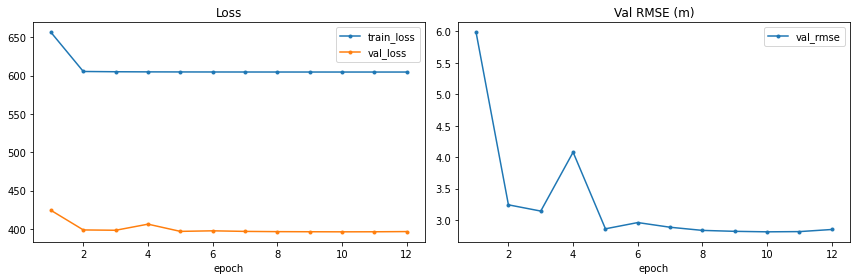

In [5]:
t0 = time.time()
training_log = fit(model, train_s, val_s, centers, save_dir=str(CKPT_DIR), **HPARAMS)
train_minutes = (time.time() - t0) / 60

log_df = pd.DataFrame(training_log)
display(log_df)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
log_df.plot(x="epoch", y=["train_loss", "val_loss"], marker=".", ax=axes[0], title="Loss")
log_df.plot(x="epoch", y="val_rmse", marker=".", ax=axes[1], title="Val RMSE (m)")
plt.tight_layout(); plt.show()

## 6. Evaluate (best checkpoint) — RMSE 1s…5s overall, per site, zero-neighbour scenes

**Decisions in this cell:** RMSE of the predicted mean at 1-5 s on the test split, overall / per site / target-only scenes (S7).

In [6]:
model.load_state_dict(torch.load(CKPT_DIR / "best_model.pt", map_location=DEVICE, weights_only=True))
model.eval()
test_s = normalize_samples(test_raw, norm_stats)

test_metrics = {}
for label, samples in test_groups(test_s).items():
    dl = create_dataloader(samples, batch_size=32, shuffle=False)
    test_metrics[label] = {**evaluate_trajectory(model, dl, DEVICE), "n": len(samples)}
display(pd.DataFrame(test_metrics).T)

,rmse_1s,rmse_2s,rmse_3s,rmse_4s,rmse_5s,rmse_avg,n
NGSIM Test Split,1.140310,1.716629,2.628058,3.857183,5.285951,2.925626,121130.0
site us-101,1.133594,1.658956,2.581822,3.860389,5.377705,2.922493,62135.0
zero-neighbour samples,1.260259,1.924321,3.023239,4.472918,6.159930,3.368133,3120.0
site i-80,1.150676,1.775217,2.678460,3.857914,5.193021,2.931058,58995.0


## 7. Collision prediction (optional)
Model's predicted target vs constant-velocity neighbours, every risk metric at its default threshold.

**Decisions in this cell:** neighbours are rolled forward at constant velocity and candidates are the nearest vehicles at the last history step, as in `--mode collisions`; only the target trajectory comes from this model.

In [7]:
collisions = None
if RUN_COLLISIONS:
    scores, gt, _ = collision_scores(model, loader, test_raw, norm_stats, COLLISION_THRESHOLD)
    collisions = {"threshold": COLLISION_THRESHOLD, "n_pairs": len(gt),
                  "n_gt_collisions": int(gt.sum()), "rows": metric_rows(scores, gt)}
    print(f"{len(gt)} pairs, {int(gt.sum())} GT collisions")
    display(pd.DataFrame(collisions["rows"]).set_index("metric"))

## 8. Save result

**Decisions in this cell:** one JSON per `EXP_NAME`; a rerun overwrites it.

In [8]:
save_result({
    "name": EXP_NAME,
    "description": DESCRIPTION,
    "model_class": type(model).__name__,
    "n_params": n_params,
    "hparams": HPARAMS,
    "data": {"locations": LOCATIONS, "debug": DEBUG},
    "train_minutes": train_minutes,
    "training_log": training_log,
    "test": test_metrics,
    "collisions": collisions,
})

Saved /home/st_students/MTP/experiments/results/cdstraj.json


PosixPath('/home/st_students/MTP/experiments/results/cdstraj.json')

## 9. Comparison & benchmarking — all results in `experiments/results/`

Ranked by overall test `rmse_avg` (best per column highlighted). Check the `data` column:
debug and full-data runs are listed together but are not comparable.
Also written to `experiments/comparison_rmse.csv` / `comparison_collisions.csv`.

**Decisions in this cell:** compares every saved result; only rows with the same `data` value are like-for-like.

,description,data,epochs,n_params,rmse_1s,rmse_2s,rmse_3s,rmse_4s,rmse_5s,rmse_avg,site us-101 avg,zero-neighbour samples avg,site i-80 avg
model,,,,,,,,,,,,,
bat,"BAT-style: centrality behaviour features + polar pooling + priority attention, 9 latent manoeuvres","us-101,i-80",12,152015,0.5486,1.2622,2.1246,3.1774,4.4043,2.3034,2.3297,4.3391,2.2746
cdstraj,CDSTraj-style: spatial-temporal interaction encoder + full-trajectory diffusion with a cross-attention transformer denoiser,"us-101,i-80",12,210492,1.1403,1.7166,2.6281,3.8572,5.2860,2.9256,2.9225,3.3681,2.9311
c2f_tp,C2F-TP-style: multimodal coarse predictor + conditional diffusion refinement (DDIM),"us-101,i-80",12,475334,5.1482,6.2205,5.8009,7.9724,6.7000,6.3684,6.2802,6.5804,6.4683


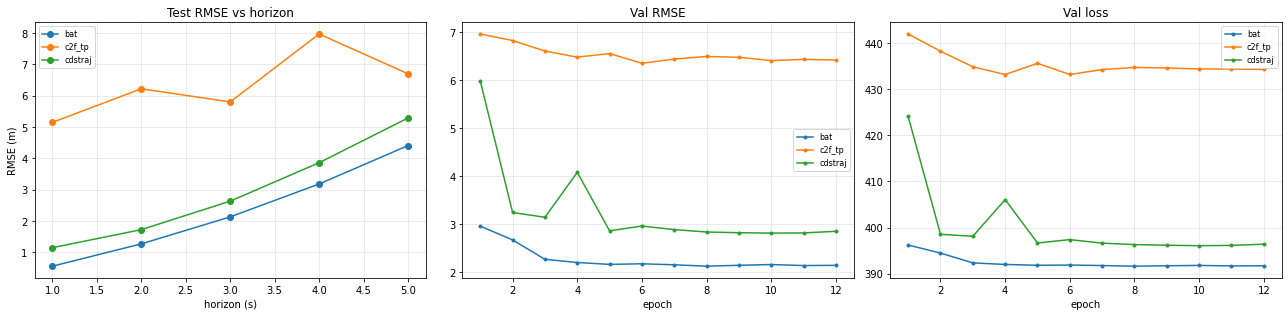

In [9]:
rmse_df, collision_df = compare()